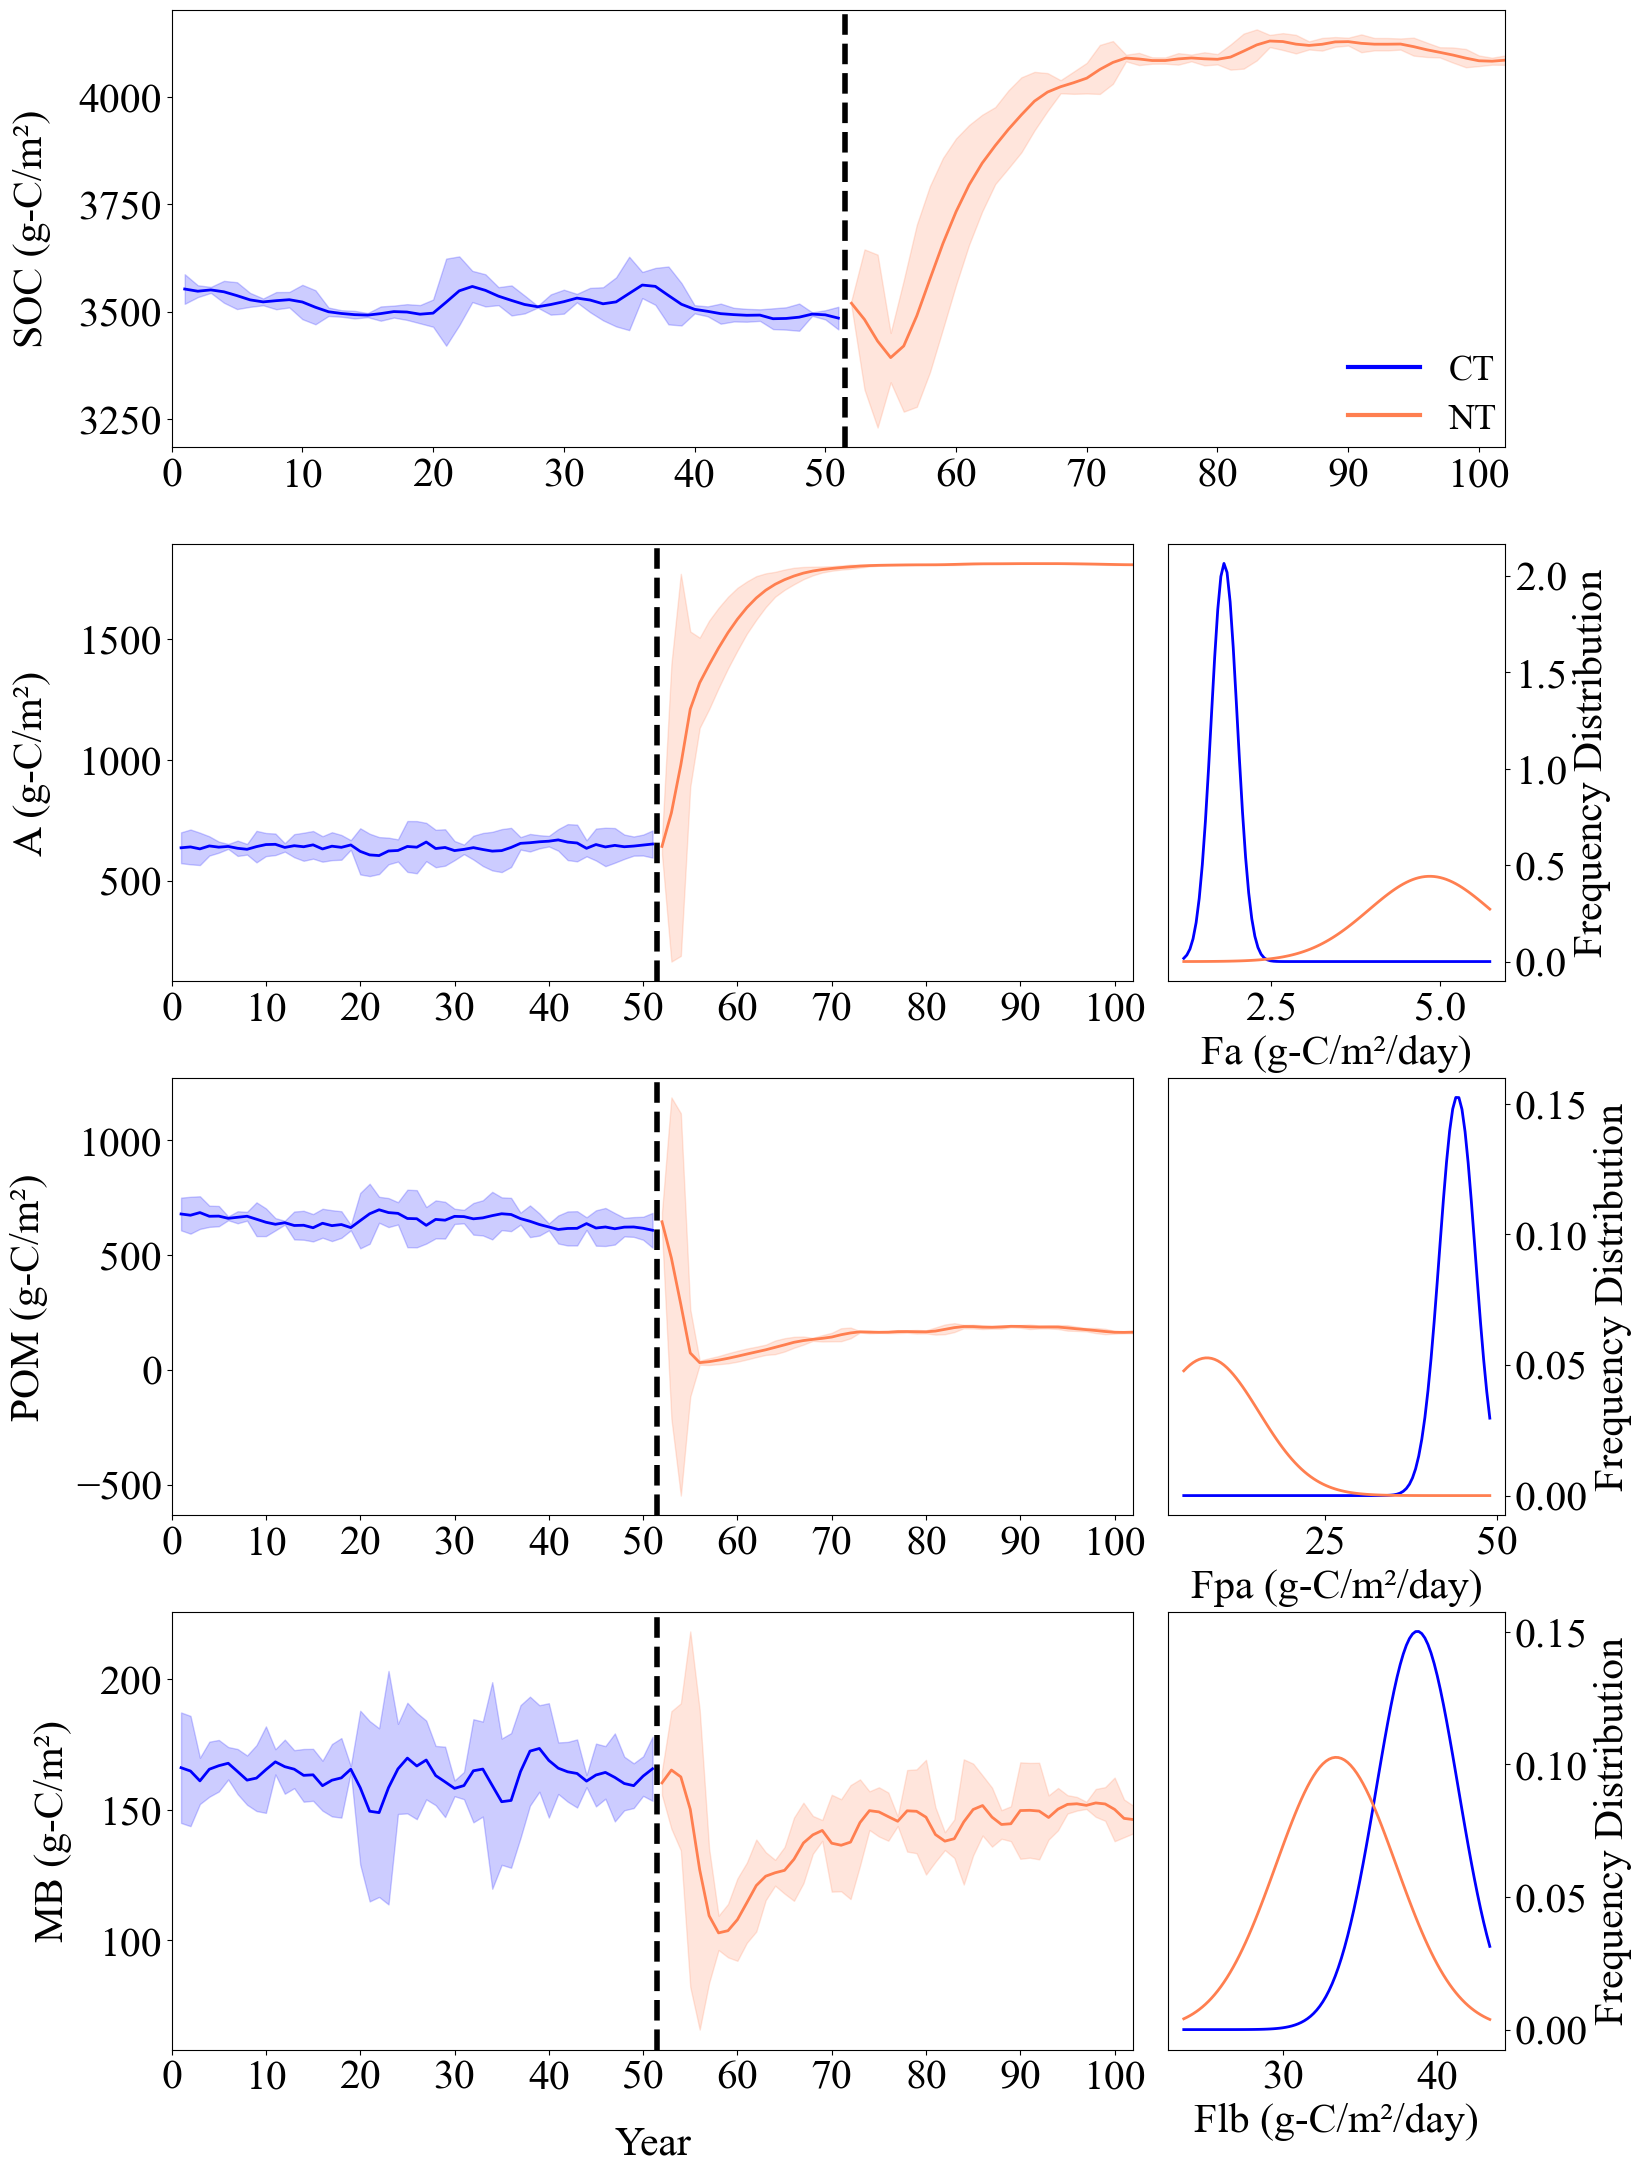

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib as mpl

# Set Times New Roman globally
mpl.rcParams['font.family'] = 'Times New Roman'

# -----------------------
TILL_START, TILL_END = 720, 770
NT_START,   NT_END   = 800, 850

# -----------------------
# LOAD DATA
# -----------------------
data = pd.read_csv('AF.csv')

# Add SOC column
data['SOC'] = data[['A', 'P', 'DOC', 'M', 'B']].sum(axis=1)

tillage_mask = data['Years'].between(TILL_START, TILL_END)
no_tillage_mask = data['Years'].between(NT_START, NT_END)

pools = ['A', 'P', 'DOC', 'M', 'B']

soc_ct = data.loc[tillage_mask, 'SOC'].mean()
soc_nt = data.loc[no_tillage_mask, 'SOC'].mean()

# -----------------------
# FUNCTIONS
# -----------------------
def calculate_rolling_stats(data, variable, window=3):
    rolling_mean = data[variable].rolling(window=window, center=True).mean()
    stderr = data[variable].rolling(window=window, center=True).std() / np.sqrt(window)
    ci = 4.303 * stderr
    lower_ci = rolling_mean - ci
    upper_ci = rolling_mean + ci
    return rolling_mean, lower_ci, upper_ci


def plot_variable_with_ci_and_normal_pdf(
    ax_ts, ax_pdf, data, variable, flux_variable,
    tillage_mask, no_tillage_mask,
    display_name=None, window=3, labelsize=25
):
    if display_name is None:
        display_name = variable

    rolling_mean, lower_ci, upper_ci = calculate_rolling_stats(data, variable, window)

    n_t = int(tillage_mask.sum())
    n_nt = int(no_tillage_mask.sum())

    # X-axis is "relative time" across both windows, with a dashed line at the gap boundary
    x_range_tillage = np.arange(1, n_t + 1)
    x_range_notillage = np.arange(n_t + 1, n_t + n_nt + 1)
    transition_x = n_t + 0.5

    # Time series plotting
    ax_ts.plot(x_range_tillage, rolling_mean[tillage_mask].values, color='blue', linewidth=2)
    ax_ts.plot(x_range_notillage, rolling_mean[no_tillage_mask].values, color='coral', linewidth=2)

    ax_ts.fill_between(
        x_range_tillage,
        lower_ci[tillage_mask].values,
        upper_ci[tillage_mask].values,
        color='blue', alpha=0.2
    )
    ax_ts.fill_between(
        x_range_notillage,
        lower_ci[no_tillage_mask].values,
        upper_ci[no_tillage_mask].values,
        color='coral', alpha=0.2
    )

    ax_ts.axvline(x=transition_x, color='black', linestyle='--', linewidth=4)

    ax_ts.set_ylabel(f'{display_name} (g-C/m\u00B2)', fontsize=labelsize, labelpad=20)
    ax_ts.set_xlim(1, n_t + n_nt)
    ax_ts.set_xticks(np.arange(0, n_t + n_nt + 1, 10))
    ax_ts.tick_params(axis='both', which='major', labelsize=labelsize)

    # Convert yearly flux to daily flux
    flux_tillage = data.loc[tillage_mask, flux_variable] * 24
    flux_notillage = data.loc[no_tillage_mask, flux_variable] * 24

    mean_flux_t, std_flux_t = flux_tillage.mean(), flux_tillage.std()
    mean_flux_nt, std_flux_nt = flux_notillage.mean(), flux_notillage.std()

    x_min = min(flux_tillage.min(), flux_notillage.min())
    x_max = max(flux_tillage.max(), flux_notillage.max())
    x_range = np.linspace(x_min, x_max, 100)

    # Guard against zero std (rare but possible)
    if std_flux_t == 0 or np.isnan(std_flux_t):
        pdf_t = np.zeros_like(x_range)
    else:
        pdf_t = stats.norm.pdf(x_range, mean_flux_t, std_flux_t)

    if std_flux_nt == 0 or np.isnan(std_flux_nt):
        pdf_nt = np.zeros_like(x_range)
    else:
        pdf_nt = stats.norm.pdf(x_range, mean_flux_nt, std_flux_nt)

    # PDF plotting
    ax_pdf.plot(x_range, pdf_t, color='blue', linewidth=2)
    ax_pdf.plot(x_range, pdf_nt, color='coral', linewidth=2)

    ax_pdf.set_xlabel(f'{flux_variable} (g-C/m²/day)', fontsize=labelsize)
    ax_pdf.set_ylabel('Frequency Distribution', fontsize=labelsize)
    ax_pdf.yaxis.set_label_position("right")
    ax_pdf.yaxis.tick_right()
    ax_pdf.tick_params(axis='both', which='major', labelsize=labelsize)


# -----------------------
# MAIN PLOTTING
# -----------------------
fig = plt.figure(figsize=(30, 24))

# -----------------------
# SOC subplot (top)
# -----------------------
ax_soc = fig.add_subplot(4, 2, 1)

rolling_mean, lower_ci, upper_ci = calculate_rolling_stats(data, 'SOC', window=3)

n_t = int(tillage_mask.sum())
n_nt = int(no_tillage_mask.sum())

x_range_tillage = np.arange(1, n_t + 1)
x_range_notillage = np.arange(n_t + 1, n_t + n_nt + 1)
transition_x = n_t + 0.5

ax_soc.plot(x_range_tillage, rolling_mean[tillage_mask].values, color='blue', linewidth=2)
ax_soc.plot(x_range_notillage, rolling_mean[no_tillage_mask].values, color='coral', linewidth=2)

ax_soc.fill_between(
    x_range_tillage,
    lower_ci[tillage_mask].values,
    upper_ci[tillage_mask].values,
    color='blue', alpha=0.2
)
ax_soc.fill_between(
    x_range_notillage,
    lower_ci[no_tillage_mask].values,
    upper_ci[no_tillage_mask].values,
    color='coral', alpha=0.2
)

ax_soc.axvline(x=transition_x, color='black', linestyle='--', linewidth=4)

ax_soc.set_ylabel('SOC (g-C/m²)', fontsize=30, labelpad=20)
ax_soc.set_xlim(1, n_t + n_nt)
ax_soc.set_xticks(np.arange(0, n_t + n_nt + 1, 10))
ax_soc.tick_params(axis='both', which='major', labelsize=30)

#ax_soc.text(0.01, 0.95, '(a)', transform=ax_soc.transAxes,
#            fontsize=28, fontweight='bold', va='top', ha='left')

# -----------------------
# A, P, B rows with PDFs
# -----------------------
variables = ['A', 'P', 'B']
display_names = ['A', 'POM', 'MB']
flux_variables = ['Fa', 'Fpa', 'Flb']
panel_labels_ts = ['(b)', '(c)', '(d)']
panel_labels_pdf = ['(e)', '(f)', '(g)']

axes_ts = []
axes_pdf = []

for i, (var, flux_var, display_name) in enumerate(zip(variables, flux_variables, display_names)):
    ax_ts = fig.add_subplot(4, 2, (i + 1) * 2 + 1)
    divider = make_axes_locatable(ax_ts)
    ax_pdf = divider.append_axes("right", size="35%", pad=0.35)

    plot_variable_with_ci_and_normal_pdf(
        ax_ts=ax_ts,
        ax_pdf=ax_pdf,
        data=data,
        variable=var,
        flux_variable=flux_var,
        tillage_mask=tillage_mask,
        no_tillage_mask=no_tillage_mask,
        display_name=display_name,
        window=3,
        labelsize=30
    )

    axes_ts.append(ax_ts)
    axes_pdf.append(ax_pdf)

axes_ts[-1].set_xlabel('Year', fontsize=30, labelpad=20)

# Separate legend handles
ct_line = plt.Line2D([0], [0], color='blue', lw=3)
nt_line = plt.Line2D([0], [0], color='coral', lw=3)

# CT legend
legend_ct = fig.legend(
    handles=[ct_line],
    labels=['CT'],
    loc='upper left',
    bbox_to_anchor=(0.44, 0.80),  # <-- adjust X, Y here
    fontsize=26,
    frameon=False
)

# NT legend
legend_nt = fig.legend(
    handles=[nt_line],
    labels=['NT'],
    loc='upper left',
    bbox_to_anchor=(0.44, 0.78),  # <-- adjust X, Y here
    fontsize=26,
    frameon=False
)


# Layout
plt.tight_layout()
plt.subplots_adjust(top=0.93, bottom=0.08)

plt.show()